# Extension: equal-dollar momentum and stock-level dynamic weights

Two changes to the Daniel and Moskowitz (2016) dynamic momentum strategy, on the replication's data (CRSP 1960–2025, all-firm breakpoints).

**Idea 1.** Hold equal dollars in every winner and loser instead of value weights, and keep scaling the whole book by the paper's weight $w_t$, re-estimated on the equal-dollar WML.

**Idea 2.** Give every stock its own weight $w_{i,t}$ from the same formula, driven by the stock's own state: has this company crashed, and how volatile is it now?

## What we find

| 19% volatility; in-sample 1960–2025 / out-of-sample 1972–2025 | Sharpe | Worst month |
|---|---|---|
| Value-weighted WML, plain (1960–2025) | 0.71 | −30% |
| Value-weighted, dynamic | 1.23 / 1.08 | −18% / −19% |
| Equal-dollar WML, plain (1960–2025) | 0.52 | −60% |
| **Idea 1:** equal-dollar, dynamic | **1.09 / 1.04** | −18% / −24% |
| **Idea 2:** stock-level weights, long-short gap left in cash | 1.10 / 0.82 | −27% / −26% |
| **Idea 2:** stock-level weights, gap closed with the market | 0.75 / 0.60 | −37% / −53% |
| **Idea 2:** stock-level weights, mix only (\$1 long, \$1 short) | 0.50 / 0.53 | −48% / −45% |

- **Idea 1 works.** Unmanaged, equal-dollar momentum is worse than value-weighted: its losers are tiny stocks that rebound violently (January 2001: losers +88%, WML −83%). But the paper's bear-market × variance signal is at least as strong for it (t = −7.6 against −6.5), and scaling the book by $w_t$ lifts the Sharpe ratio from 0.52 to about 1.05. After 2013 it beats the value-weighted version (0.94 against 0.65 out of sample).
- **Idea 2 does not identify the option-like companies.** Re-mixing the stocks inside each leg by their own weights leaves the Sharpe ratio where it started (0.50 against 0.52 in-sample).
- **What idea 2 does do is cut the whole short leg before crashes.** Loser weights fall to 0–15% of normal going into January 2001, April 2009, April 2020 and January 2023, because every loser's variance spikes together. That is the paper's book-level effect arriving bottom-up. It only pays if the gap is left in cash, which makes the book net long the market (beta 0.5); the edge fades out of sample (0.82) and is gone after 2013 (appraisal ratio 0.05).
- **Why the stock's own state fails.** 89% of losers are already down over two years, so the flag barely separates them. The most volatile losers are the best shorts on average (0.73% a month against −0.05% for the calmest), so dividing by own variance moves money away from where momentum pays. And in the crash months the calm and volatile halves of the loser leg rebound by similar amounts: the squeeze hits the whole leg and is timed by the market, not by the company.

## Definitions

The paper's weight on WML, set at the end of month $t-1$:

$$w_{t-1} = \frac{1}{2\lambda}\,\frac{\mu_{t-1}}{\sigma^2_{t-1}}$$

$$\mu_{t-1} = \hat\gamma_0 + \hat\gamma_1\, I_{B,t-1}\,\hat\sigma^2_{m,t-1}$$

Here $I_{B,t-1}$ flags a bear market (market down over the past 24 months), $\hat\sigma^2_{m,t-1}$ is the market's variance over the past 126 days, and $\sigma^2_{t-1}$ is the forecast variance of WML (GJR-GARCH combined with 126-day realized volatility). $\lambda$ is set so that the strategy runs at 19% volatility.

**Idea 1** changes the portfolio, not the formula. With $W$ the winner decile and $L$ the loser decile:

$$R^{EW}_{t} = \frac{1}{N_W}\sum_{i\in W} r_{i,t} \;-\; \frac{1}{N_L}\sum_{i\in L} r_{i,t}$$

$$\text{PnL}_t = w_{t-1}\,R^{EW}_{t}$$

$\mu_{t-1}$ and $\sigma^2_{t-1}$ are re-estimated on $R^{EW}$.

**Idea 2** applies the formula stock by stock. Let $s_i = +1$ for winners and $-1$ for losers. Each stock's momentum payoff is its return against the market:

$$x_{i,t} = s_i\,(r_{i,t} - r_{m,t})$$

Its expected payoff comes from a pooled regression, one per leg, on the stock's own state:

$$\mu_{i,t-1} = \hat\gamma_0 + \hat\gamma_1\, I_{B,i,t-1}\,\sigma^2_{i,t-1}$$

$I_{B,i,t-1} = 1$ if the stock's own return over months $t-24$ to $t-1$ is negative, and $\sigma^2_{i,t-1}$ is the variance of its daily returns over the previous six calendar months (about 126 days). The stock's weight is

$$w_{i,t-1} = \frac{\max(\mu_{i,t-1},\,0)}{\sigma^2_{i,t-1}}$$

The floor at zero means a weight can shrink a position to nothing but never flip it. Three books are built from these weights:

$$\text{cash:}\quad \text{PnL}_t = \frac{1}{N_W}\sum_{i\in W} w_{i,t-1}\,(r_{i,t}-r_{f,t}) \;-\; \frac{1}{N_L}\sum_{i\in L} w_{i,t-1}\,(r_{i,t}-r_{f,t})$$

$$\text{market offset:}\quad \text{PnL}_t = \frac{1}{N_W}\sum_{i\in W} w_{i,t-1}\,(r_{i,t}-r_{m,t}) \;-\; \frac{1}{N_L}\sum_{i\in L} w_{i,t-1}\,(r_{i,t}-r_{m,t})$$

$$\text{mix only:}\quad \text{PnL}_t = \sum_{i\in W} \frac{w_{i,t-1}}{\sum_{W} w_{j,t-1}}\,r_{i,t} \;-\; \sum_{i\in L} \frac{w_{i,t-1}}{\sum_{L} w_{j,t-1}}\,r_{i,t}$$

With $w_{i} = 1$ for every stock, all three collapse to $R^{EW}_t$. In the first two the long and short sides can differ in size; in the third they cannot.

"In-sample" (IS) uses full-sample regression coefficients, as the paper does. "Out-of-sample" (OOS) uses only data before month $t$.

## Setup

Run from the project root. Needs `pandas`, `pyarrow`, `statsmodels`, `arch` and `matplotlib` (tested with pandas 2.3). Intermediate tables are cached in `data/processed/extension/`, so a re-run takes about a minute; delete that folder to rebuild from the raw CRSP files.

In [1]:
from pathlib import Path
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

ROOT = Path.cwd()
assert (ROOT / "src" / "config.py").exists(), "Run this notebook from the project root (the folder holding src/ and data/)."
sys.path.insert(0, str(ROOT / "src"))

import dynamic, garch, tables                          # the team's replication code, reused unchanged
from config import PROCESSED, RAW, RESULTS, FULL, in_sample
from load_data import load, ff_monthly, ff_daily, past_126day_variance

warnings.simplefilter("ignore", FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}", "display.width", 200)

SCHEME = "allfirm"                                     # the paper's breakpoints; "nyse" also works
DECILE_COLUMN = {"allfirm": "d_all", "nyse": "d_nyse"}[SCHEME]
EXT = PROCESSED / "extension"                          # everything this notebook caches
EXT.mkdir(parents=True, exist_ok=True)
TARGET_VOL = dynamic.PERFORMANCE_VOL                   # 19% a year, as in the paper's Figure 5
OOS_START = "1970-01"                                  # same out-of-sample start as the replication

## Data

The stocks, deciles and formation rules are the replication's own (`data/processed/members.parquet`). Only two things are new: daily returns of the equal-dollar legs, and each stock's own trailing return and variance.

In [2]:
# Daily pass: one read of the 816 CRSP daily files (about a minute). Produces two cached tables.
#   stock_month_stats   per stock and month: number of daily returns, their sum and sum of squares
#                       (enough to rebuild any trailing variance without keeping the daily data)
#   ew_daily_legs       daily return of the equal-dollar loser (D1) and winner (D10) legs
STATS_FILE = EXT / "stock_month_stats.parquet"
EW_DAILY_FILE = EXT / f"ew_daily_legs_{SCHEME}.parquet"

members = (pd.read_parquet(PROCESSED / "members.parquet", columns=["month", "permno", "me", DECILE_COLUMN])
           .rename(columns={DECILE_COLUMN: "decile"}))
held = members[members.decile.isin([1, 10])]           # the stocks WML holds: losers and winners
eligible_permnos = pd.Index(members.permno.unique())


def process_daily_file(path, held_by_month):
    d = pd.read_parquet(path, columns=["permno", "dlycaldt", "dlyret"])
    d["ret"] = pd.to_numeric(d.dlyret, errors="coerce")
    d["date"] = pd.to_datetime(d.dlycaldt)
    d = d[d.ret.notna() & d.permno.isin(eligible_permnos)]
    if d.empty:
        return None, None
    month = d.date.iloc[0].to_period("M")

    by_stock = d.groupby("permno").ret
    stats = pd.DataFrame({"n": by_stock.size(), "s1": by_stock.sum(),
                          "s2": d.ret.pow(2).groupby(d.permno).sum()}).reset_index()
    stats.insert(1, "month", month)

    legs = None
    if month in held_by_month:
        x = d.merge(held_by_month[month], on="permno").sort_values(["permno", "date"])
        # equal dollars at the start of the month, then buy and hold (so days compound to the month)
        growth = (1 + x.ret).groupby(x.permno).cumprod()
        x["w"] = growth.groupby(x.permno).shift(1).fillna(1.0)
        x["w_ret"] = x.w * x.ret
        legs = x.groupby(["date", "decile"]).agg(w_ret=("w_ret", "sum"), w=("w", "sum"),
                                                 n=("permno", "size")).reset_index()
        legs["ret"] = legs.w_ret / legs.w
        legs = legs[["date", "decile", "ret", "n"]]
    return stats, legs


if not (STATS_FILE.exists() and EW_DAILY_FILE.exists()):
    start = time.time()
    held_by_month = {m: g[["permno", "decile"]] for m, g in held.groupby("month")}
    parts = [process_daily_file(p, held_by_month) for p in sorted((RAW / "crsp.dsf_v2").glob("*.parquet"))]
    pd.concat([s for s, _ in parts if s is not None], ignore_index=True).to_parquet(STATS_FILE, index=False)
    pd.concat([l for _, l in parts if l is not None], ignore_index=True).to_parquet(EW_DAILY_FILE, index=False)
    print(f"daily pass: {time.time() - start:.0f}s")

stats = pd.read_parquet(STATS_FILE)
ew_daily = pd.read_parquet(EW_DAILY_FILE).pivot(index="date", columns="decile", values="ret")
print(f"stock-months with daily data: {len(stats):,} | EW daily legs: {ew_daily.index[0].date()} to {ew_daily.index[-1].date()}")

stock-months with daily data: 3,561,695 | EW daily legs: 1959-02-02 to 2025-12-31


In [3]:
# Value-weighted baseline: the team's portfolios and weights, rebuilt with their own functions.
monthly_vw, daily_vw, vol_vw = load(SCHEME)
w_vw, _, _ = dynamic.weights(monthly_vw, vol_vw)
strat_vw = dynamic.monthly_returns(w_vw, monthly_vw)

committed = pd.read_csv(RESULTS / f"strategies_{SCHEME}.csv", index_col=0)
gap = np.nanmax(np.abs(strat_vw.values - committed.values))
print(f"baseline vs results/strategies_{SCHEME}.csv: largest difference {gap:.1e}")
assert gap < 1e-4, "baseline does not reproduce the committed replication results"

baseline vs results/strategies_allfirm.csv: largest difference 6.7e-16


In [4]:
# Monthly stock returns and each stock's own state at the end of month t-1.
keep = ["permno", "mthcaldt", "mthret"]
msf = pd.concat(pd.read_parquet(f, columns=keep) for f in sorted((RAW / "crsp.msf_v2").glob("*.parquet")))
msf = msf[msf.permno.isin(eligible_permnos)]
msf["month"] = pd.to_datetime(msf.mthcaldt).dt.to_period("M")
msf["ret"] = pd.to_numeric(msf.mthret, errors="coerce")
months = pd.period_range(msf.month.min(), msf.month.max(), freq="M", name="month")


def wide(df, col):                                      # months x stocks
    return df.pivot(index="month", columns="permno", values=col).reindex(months)


def long(df, name):                                     # back to one row per (month, stock)
    return df.stack(future_stack=True).dropna().rename(name).reset_index()


ret = wide(msf, "ret")

# own 24-month return, months t-24 .. t-1 (at least 12 months of history)
with np.errstate(divide="ignore"):
    own_24m = np.expm1(np.log1p(ret).rolling(24, min_periods=12).sum().shift(1))

# own variance of daily returns over the six calendar months before month t (about 126 trading days), annualized
n6, s1, s2 = (wide(stats, c).rolling(6, min_periods=1).sum().shift(1) for c in ["n", "s1", "s2"])
own_var = ((s2 - s1 ** 2 / n6) / (n6 - 1) * 252).where(n6 >= 60)

panel = (held.merge(long(ret, "ret"), on=["month", "permno"])            # held stocks with a return in month t
             .merge(long(own_24m, "own_24m"), on=["month", "permno"], how="left")
             .merge(long(own_var, "own_var"), on=["month", "permno"], how="left"))
panel = panel[panel.month >= "1960-01"].reset_index(drop=True)
del n6, s1, s2
print(f"{len(panel):,} stock-months in D1 and D10, {panel.month.min()} to {panel.month.max()}; "
      f"own state missing for {panel[['own_24m', 'own_var']].isna().any(axis=1).mean():.1%}")

631,062 stock-months in D1 and D10, 1960-01 to 2025-12; own state missing for 0.1%


In [5]:
# Shared helpers: market data, performance numbers and plots.
ffm, ffd = ff_monthly(), ff_daily()
BLUE, ORANGE, AQUA, VIOLET, GREY, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#52514e", "#0b0b0b", "#e4e3df"
PERIODS = {"1960-2025": ("1960-01", "2025-12"), "1972-2025 (all out-of-sample)": ("1972-01", "2025-12"),
           "2013:04-2025 (after the paper)": ("2013-04", "2025-12")}


def to_target_vol(r):
    """Scale a monthly return series by one constant so its full-sample volatility is 19% a year."""
    return r * TARGET_VOL / (r.std() * np.sqrt(12))


def performance(strategies, start, end):
    rows = {}
    for name, r in strategies.items():
        r = r.loc[start:end].dropna()
        wealth = (1 + r).cumprod()
        capm = sm.OLS(r, sm.add_constant(ffm.mktrf.reindex(r.index))).fit()
        rows[name] = {"months": len(r), "mean %/yr": r.mean() * 1200, "vol %/yr": r.std() * np.sqrt(12) * 100,
                      "Sharpe": r.mean() / r.std() * np.sqrt(12), "mkt beta": capm.params["mktrf"],
                      "appraisal": capm.params["const"] / capm.resid.std() * np.sqrt(12), "skew": r.skew(),
                      "worst month %": r.min() * 100, "max drawdown %": (wealth / wealth.cummax() - 1).min() * 100}
    return pd.DataFrame(rows).T.astype({"months": int})


def plot_cumulative(strategies, colors, title, start="1960-01"):
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    last = strategies.index[-1].to_timestamp()
    ends = {}
    for (name, r), color in zip(strategies.items(), colors):
        r = r.loc[start:].dropna()
        y = np.log1p(r).cumsum()
        sharpe = r.mean() / r.std() * np.sqrt(12)
        ax.plot(r.index.to_timestamp(), y, color=color, lw=2, label=f"{name} (Sharpe {sharpe:.2f})")
        ends[name] = y.iloc[-1]
    gap, placed = 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0]), -np.inf
    for name, y_end in sorted(ends.items(), key=lambda kv: kv[1]):     # end labels, nudged apart where lines finish close
        placed = max(y_end, placed + gap)
        ax.annotate(name, (last, placed), xytext=(5, 0), textcoords="offset points", fontsize=9, color=INK, va="center")
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylabel("Cumulative log return", color=GREY)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=GREY, labelsize=9)
    ax.set_xlim(right=last + pd.Timedelta(days=365 * 9))
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    fig.tight_layout(); plt.show()

## Idea 1: equal-dollar WML, book scaled by $w_t$

Performance tables below put every series at 19% volatility. *mkt beta* is the CAPM beta and *appraisal* is the CAPM alpha divided by residual volatility (annualized), so a net long book cannot pass off the equity premium as skill. Out-of-sample rows start in 1972 for the book-level strategies and 1970 for the stock-level ones; the second table puts everything on 1972–2025.

In [6]:
# Idea 1, step 1: equal-dollar winner and loser legs, monthly and daily.
legs = panel.groupby(["month", "decile"]).ret.mean().unstack()
monthly_ew = pd.DataFrame({"D1": legs[1], "D10": legs[10], "WML": legs[10] - legs[1]}).join(ffm, how="inner")
monthly_ew["var_m"] = past_126day_variance(ffd.mkt).reindex(monthly_ew.index)

daily_ew = pd.DataFrame({"D1": ew_daily[1], "D10": ew_daily[10], "WML": ew_daily[10] - ew_daily[1]}).join(ffd, how="inner")

# check: the daily legs compound to the monthly legs
compounded = (1 + daily_ew[["D1", "D10"]]).groupby(daily_ew.index.to_period("M")).prod() - 1
check = (compounded - monthly_ew[["D1", "D10"]]).dropna()
print("daily legs compounded vs monthly legs: correlation",
      {c: round(compounded[c].corr(monthly_ew[c]), 4) for c in ["D1", "D10"]},
      "| median absolute gap", {c: f"{check[c].abs().median():.1e}" for c in check})

both = pd.DataFrame({"equal-dollar WML": monthly_ew.WML, "value-weighted WML": monthly_vw.WML}).loc["1960-01":]
print(f"correlation of equal-dollar and value-weighted WML: {both.corr().iloc[0, 1]:.2f}")
display(pd.concat({"equal-dollar": tables.portfolio_stats(in_sample(monthly_ew, FULL), portfolios=["D1", "D10"]),
                   "value-weighted": tables.portfolio_stats(in_sample(monthly_vw, FULL), portfolios=["D1", "D10"])}, axis=1))

daily legs compounded vs monthly legs: correlation {'D1': np.float64(0.9998), 'D10': np.float64(0.9999)} | median absolute gap {'D1': '4.0e-04', 'D10': '2.2e-04'}
correlation of equal-dollar and value-weighted WML: 0.77


equal-dollar                   value-weighted                  
                   D1   D10   WML   Mkt             D1   D10   WML   Mkt
mean             1.87 15.61 13.74  7.06          -6.27 14.79 21.06  7.06
sd              35.90 24.21 26.30 15.40          34.00 22.76 29.67 15.40
alpha           -8.82  6.78 15.60   NaN         -17.95  6.36 24.31   NaN
t(alpha)        -2.60  3.72  4.83   NaN          -6.42  3.82  6.79   NaN
beta             1.51  1.25 -0.26  1.00           1.65  1.19 -0.46  1.00
SR               0.05  0.64  0.52  0.46          -0.18  0.65  0.71  0.46
sk(m)            0.55 -0.71 -8.39 -0.72          -0.07 -0.60 -2.10 -0.72

In [7]:
# Idea 1, step 2: re-estimate the dynamic weight on the equal-dollar WML (same code as the replication).
VOL_EW_FILE = EXT / f"wml_vol_ew_{SCHEME}.parquet"
if VOL_EW_FILE.exists():
    vol_ew = pd.read_parquet(VOL_EW_FILE).set_index("month")
else:                                                   # about 670 GARCH fits; a few minutes
    vol_ew = garch.volatility_table(daily_ew.WML.dropna(), OOS_START, verbose=False, workers=os.cpu_count())
    vol_ew.reset_index().to_parquet(VOL_EW_FILE, index=False)

w_ew, mean_fit_ew, vol_fit_ew = dynamic.weights(monthly_ew, vol_ew)
strat_ew = dynamic.monthly_returns(w_ew, monthly_ew)

mean_table, vol_table = dynamic.forecast_regressions(mean_fit_ew, vol_fit_ew)
_, mean_fit_vw, vol_fit_vw = dynamic.weights(monthly_vw, vol_vw)
mean_table_vw, vol_table_vw = dynamic.forecast_regressions(mean_fit_vw, vol_fit_vw)
print("Expected return: WML on (bear market x market variance); constant in %/month")
display(pd.concat({"equal-dollar": mean_table, "value-weighted": mean_table_vw}, axis=1))
print("Expected volatility: realized WML volatility on the GARCH forecast and 126-day volatility")
display(pd.concat({"equal-dollar": vol_table, "value-weighted": vol_table_vw}, axis=1))

Expected return: WML on (bear market x market variance); constant in %/month


,equal-dollar,value-weighted
,WML,WML
const,1.643 [6.12],2.237 [7.31]
IB*var_m,-0.670 [-7.64],-0.649 [-6.50]
R2 (%),6.9,5.1
N,792,792


Expected volatility: realized WML volatility on the GARCH forecast and 126-day volatility


,equal-dollar,value-weighted
,realized vol,realized vol
const,0.001 [0.45],0.002 [1.07]
garch_is,0.570 [13.64],0.662 [15.07]
rv126,0.325 [8.11],0.250 [5.84]
R2 (%),52.8,66.9
N,792,792


1960-2025


,months,mean %/yr,vol %/yr,Sharpe,mkt beta,appraisal,skew,worst month %,max drawdown %
VW plain,792,13.48,19.00,0.71,-0.29,0.84,-1.15,-30.35,-65.04
VW dynamic (IS),792,23.44,19.00,1.23,-0.03,1.24,0.65,-17.51,-32.60
VW dynamic (OOS),648,20.46,19.00,1.08,-0.04,1.09,0.54,-19.29,-33.33
EW plain,792,9.92,19.00,0.52,-0.19,0.60,-2.76,-59.80,-76.15
EW constant-vol,792,16.40,19.00,0.86,-0.12,0.91,-1.18,-37.43,-50.89
EW dynamic (IS),792,20.80,19.00,1.09,0.12,1.05,2.04,-18.23,-24.76
EW dynamic (OOS),648,19.70,19.00,1.04,0.12,0.99,0.29,-24.31,-38.37


1972-2025 (all out-of-sample)


,months,mean %/yr,vol %/yr,Sharpe,mkt beta,appraisal,skew,worst month %,max drawdown %
VW plain,648,13.65,20.20,0.68,-0.32,0.82,-1.15,-30.35,-65.04
VW dynamic (IS),648,21.98,18.62,1.18,-0.01,1.18,0.69,-17.51,-32.60
VW dynamic (OOS),648,20.46,19.00,1.08,-0.04,1.09,0.54,-19.29,-33.33
EW plain,648,9.44,20.12,0.47,-0.20,0.55,-2.77,-59.80,-76.15
EW constant-vol,648,15.59,19.25,0.81,-0.10,0.85,-1.24,-37.43,-50.89
EW dynamic (IS),648,20.36,19.29,1.06,0.17,1.00,2.53,-17.25,-24.76
EW dynamic (OOS),648,19.70,19.00,1.04,0.12,0.99,0.29,-24.31,-38.37


2013:04-2025 (after the paper)


,months,mean %/yr,vol %/yr,Sharpe,mkt beta,appraisal,skew,worst month %,max drawdown %
VW plain,153,10.79,21.38,0.50,-0.53,0.88,-0.75,-22.84,-37.68
VW dynamic (IS),153,7.43,10.89,0.68,-0.10,0.80,0.76,-8.67,-12.07
VW dynamic (OOS),153,6.38,9.87,0.65,-0.09,0.77,0.81,-8.11,-11.22
EW plain,153,13.41,18.44,0.73,-0.38,1.04,-1.25,-25.37,-40.38
EW constant-vol,153,11.57,13.66,0.85,-0.25,1.12,-0.79,-12.12,-24.28
EW dynamic (IS),153,10.45,10.70,0.98,-0.01,0.99,0.78,-8.85,-11.34
EW dynamic (OOS),153,9.44,10.01,0.94,-0.02,0.97,0.43,-8.86,-11.27


Worst five months of the unscaled equal-dollar WML, with the two legs and the market (%)


,WML,D1,D10,mkt,VW WML
month,,,,,
2001-01,-82.78,87.61,4.83,3.79,-47.39
2002-11,-41.48,47.03,5.56,6.08,-37.59
2009-04,-38.38,43.80,5.42,10.18,-45.24
2023-01,-35.11,39.89,4.78,6.96,-35.66
1975-01,-30.95,47.84,16.90,14.25,-20.10


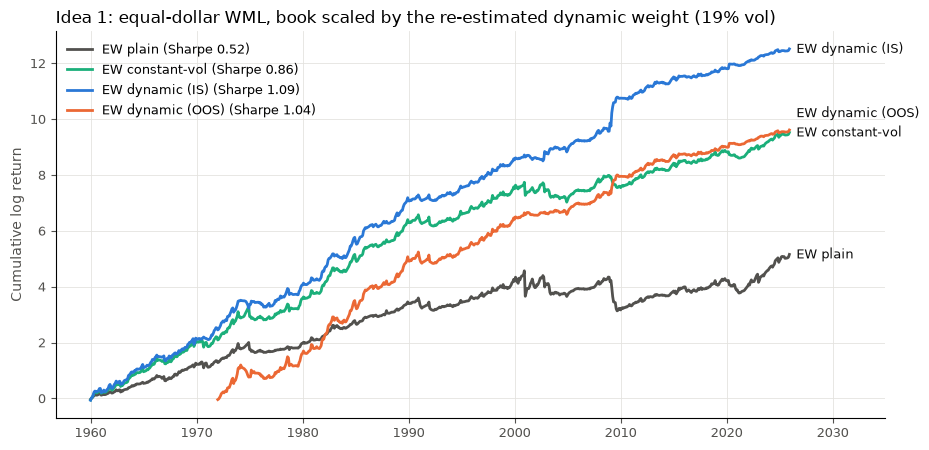

In [8]:
# Idea 1 results. Every series below is scaled to 19% volatility so tails are comparable.
idea1 = pd.DataFrame({
    "VW plain": to_target_vol(strat_vw["WML"]),
    "VW dynamic (IS)": strat_vw["dyn (IS)"],
    "VW dynamic (OOS)": strat_vw["dyn (OOS)"],
    "EW plain": to_target_vol(strat_ew["WML"]),
    "EW constant-vol": strat_ew["cvol"],
    "EW dynamic (IS)": strat_ew["dyn (IS)"],
    "EW dynamic (OOS)": strat_ew["dyn (OOS)"],
})
for label, (start, end) in PERIODS.items():
    print(label); display(performance(idea1, start, end))

print("Worst five months of the unscaled equal-dollar WML, with the two legs and the market (%)")
display((monthly_ew.loc["1960-01":].nsmallest(5, "WML")[["WML", "D1", "D10", "mkt"]] * 100)
        .join((monthly_vw.WML * 100).rename("VW WML")))

plot_cumulative(idea1[["EW plain", "EW constant-vol", "EW dynamic (IS)", "EW dynamic (OOS)"]],
                [GREY, AQUA, BLUE, ORANGE], "Idea 1: equal-dollar WML, book scaled by the re-estimated dynamic weight (19% vol)")

## Idea 2: a weight for every stock

Position returns are in % per month. The row to read is `bear_var` in column (4): it plays the role of the paper's bear-market × variance coefficient, one stock at a time.

In [9]:
# Idea 2, step 1: each stock's own state and the pooled forecasting regressions.
p = panel.dropna(subset=["own_24m", "own_var"]).copy()
p["leg"] = np.where(p.decile == 10, "winners", "losers")
p["side"] = np.where(p.decile == 10, 1.0, -1.0)
p = p.join(ffm[["mkt", "rf"]], on="month")
p["x"] = p.side * (p.ret - p.mkt)                        # position return against the market: the stock's momentum payoff
p["x_cash"] = p.side * (p.ret - p.rf)                    # position return against cash
p["bear"] = (p.own_24m < 0).astype(float)                # the stock itself is down over the past two years

# tame the tails of own variance inside each leg and month (uses only information known at t-1)
by_leg_month = p.groupby(["month", "leg"]).own_var
p["var"] = p.own_var.clip(by_leg_month.transform(lambda v: v.quantile(0.05)),
                          by_leg_month.transform(lambda v: v.quantile(0.95)))
p["bear_var"] = p.bear * p["var"]

state = p.groupby("leg").agg(stock_months=("x", "size"), share_own_bear=("bear", "mean"),
                             median_vol=("var", lambda v: np.sqrt(v.median())),
                             mean_position_return_pct=("x", lambda v: v.mean() * 100))
display(state)


def pooled(df, columns):
    """Pooled OLS across stock-months, standard errors clustered by month."""
    fit = sm.OLS(df.x, sm.add_constant(df[columns])).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(df.month)[0]})
    return fit


fits, rows = {}, {}
for leg, df in p.groupby("leg"):
    fits[leg] = pooled(df, ["bear_var"])                 # the stock-level version of Table 5, column (4)
    full = pooled(df, ["bear", "var", "bear_var"])       # column (5), for information
    for name, fit in [("(4)", fits[leg]), ("(5)", full)]:
        rows[leg, name] = {v: f"{fit.params[v] * 100:.3f} [{fit.tvalues[v]:.2f}]"
                           for v in fit.params.index} | {"N": f"{int(fit.nobs):,}"}
print("Position return (%/month) on the stock's own state; variance is annualized. [t] clustered by month.")
display(pd.DataFrame(rows).reindex(["const", "bear", "var", "bear_var", "N"]).fillna(""))

,stock_months,share_own_bear,median_vol,mean_position_return_pct
leg,,,,
losers,314390,0.89,0.83,0.38
winners,316350,0.12,0.54,0.73


Position return (%/month) on the stock's own state; variance is annualized. [t] clustered by month.


losers                       winners                
                     (4)             (5)           (4)             (5)
const       0.886 [3.65]    0.680 [2.87]  0.684 [4.06]    0.917 [4.40]
bear                        0.101 [0.34]                -0.973 [-3.06]
var                         1.360 [4.31]                -0.429 [-0.67]
bear_var  -0.439 [-1.85]  -1.766 [-5.48]  0.512 [1.49]    1.440 [2.76]
N                314,390         314,390       316,350         316,350

In [10]:
# Idea 2, step 2: stock-level weights w_i = max(mu_i, 0) / sigma_i^2 and the portfolios they give.
# in-sample forecast: full-sample coefficients, as in the paper
p["mu_is"] = np.nan
for leg, fit in fits.items():
    rows_leg = p.leg == leg
    p.loc[rows_leg, "mu_is"] = fit.params["const"] + fit.params["bear_var"] * p.loc[rows_leg, "bear_var"]

# out-of-sample forecast: coefficients from all months before t (expanding window)
sums = (p.assign(n=1.0, z=p.bear_var, zz=p.bear_var ** 2, zx=p.bear_var * p.x)
          .groupby(["leg", "month"])[["n", "z", "zz", "x", "zx"]].sum())
past = sums.groupby(level="leg").cumsum().groupby(level="leg").shift(1)          # sums over months < t
slope = (past.zx - past.z * past.x / past.n) / (past.zz - past.z ** 2 / past.n)
coef = pd.DataFrame({"g0": (past.x - slope * past.z) / past.n, "g1": slope})
coef = coef[coef.index.get_level_values("month") >= OOS_START]
p = p.join(coef, on=["leg", "month"])
p["mu_oos"] = p.g0 + p.g1 * p.bear_var

p["w_is"] = p.mu_is.clip(lower=0) / p["var"]            # floor at zero: resize positions, never flip them
p["w_oos"] = p.mu_oos.clip(lower=0) / p["var"]
p["w_ivol"] = 1 / np.sqrt(p["var"])                     # stock-level constant-vol: no return forecast


def bottom_up(weight, offset):
    """Equal dollars per stock, each position multiplied by its own weight. The legs are not rebalanced
    against each other, so the long and short sides can differ in size. The gap is either left in cash
    (offset="cash": the book runs net long when shorts are cut) or closed with the market index
    (offset="market": the book stays dollar-neutral)."""
    position = p.x_cash if offset == "cash" else p.x
    leg_ret = (p[weight] * position).groupby([p.month, p.leg]).mean().unstack()
    return leg_ret.sum(axis=1, min_count=2)


def composition_only(weight):
    """Weights renormalized to $1 long and $1 short: only the mix inside each leg changes."""
    wr = (p[weight] * p.ret).groupby([p.month, p.leg]).sum().unstack()
    w = p[weight].groupby([p.month, p.leg]).sum(min_count=1).unstack()
    leg_ret = wr / w.where(w > 0)
    return leg_ret["winners"] - leg_ret["losers"]


idea2_raw = pd.DataFrame({
    "Stock dynamic, cash (IS)": bottom_up("w_is", "cash"),
    "Stock dynamic, cash (OOS)": bottom_up("w_oos", "cash"),
    "Stock dynamic, mkt offset (IS)": bottom_up("w_is", "market"),
    "Stock dynamic, mkt offset (OOS)": bottom_up("w_oos", "market"),
    "Stock mix only (IS)": composition_only("w_is"),
    "Stock mix only (OOS)": composition_only("w_oos"),
})
idea2 = idea2_raw.apply(to_target_vol)
empty = idea2_raw.loc["1972-01":].isna().sum()
print("months with an empty leg (no position taken), 1972 on:", empty[empty > 0].to_dict() or "none")

everything = pd.concat([idea1, idea2], axis=1)
shown = ["EW plain", "EW dynamic (IS)", "EW dynamic (OOS)"] + list(idea2)
for label, (start, end) in PERIODS.items():
    print(label); display(performance(everything[shown], start, end))

months with an empty leg (no position taken), 1972 on: {'Stock mix only (OOS)': 1}
1960-2025


,months,mean %/yr,vol %/yr,Sharpe,mkt beta,appraisal,skew,worst month %,max drawdown %
EW plain,792,9.92,19.00,0.52,-0.19,0.60,-2.76,-59.80,-76.15
EW dynamic (IS),792,20.80,19.00,1.09,0.12,1.05,2.04,-18.23,-24.76
EW dynamic (OOS),648,19.70,19.00,1.04,0.12,0.99,0.29,-24.31,-38.37
"Stock dynamic, cash (IS)",792,20.98,19.00,1.10,0.50,1.00,-0.06,-26.95,-42.03
"Stock dynamic, cash (OOS)",672,13.64,19.00,0.72,0.83,0.54,-0.78,-43.41,-63.65
"Stock dynamic, mkt offset (IS)",792,14.33,19.00,0.75,-0.16,0.82,-0.91,-36.83,-55.68
"Stock dynamic, mkt offset (OOS)",672,11.02,19.00,0.58,-0.13,0.64,-2.43,-52.83,-55.50
Stock mix only (IS),792,9.43,19.00,0.50,-0.25,0.60,-1.91,-48.48,-69.47
Stock mix only (OOS),671,9.81,19.00,0.52,-0.22,0.61,-1.49,-45.01,-46.90


1972-2025 (all out-of-sample)


,months,mean %/yr,vol %/yr,Sharpe,mkt beta,appraisal,skew,worst month %,max drawdown %
EW plain,648,9.44,20.12,0.47,-0.20,0.55,-2.77,-59.80,-76.15
EW dynamic (IS),648,20.36,19.29,1.06,0.17,1.00,2.53,-17.25,-24.76
EW dynamic (OOS),648,19.70,19.00,1.04,0.12,0.99,0.29,-24.31,-38.37
"Stock dynamic, cash (IS)",648,17.12,16.51,1.04,0.60,0.93,-0.16,-26.95,-36.30
"Stock dynamic, cash (OOS)",648,13.93,16.93,0.82,0.75,0.68,0.16,-25.97,-48.73
"Stock dynamic, mkt offset (IS)",648,11.14,17.03,0.65,-0.14,0.72,-1.18,-36.83,-55.68
"Stock dynamic, mkt offset (OOS)",648,11.21,18.70,0.60,-0.15,0.66,-2.59,-52.83,-55.50
Stock mix only (IS),648,8.68,19.93,0.44,-0.26,0.55,-1.93,-48.48,-69.47
Stock mix only (OOS),647,10.07,18.96,0.53,-0.22,0.63,-1.52,-45.01,-46.90


2013:04-2025 (after the paper)


,months,mean %/yr,vol %/yr,Sharpe,mkt beta,appraisal,skew,worst month %,max drawdown %
EW plain,153,13.41,18.44,0.73,-0.38,1.04,-1.25,-25.37,-40.38
EW dynamic (IS),153,10.45,10.70,0.98,-0.01,0.99,0.78,-8.85,-11.34
EW dynamic (OOS),153,9.44,10.01,0.94,-0.02,0.97,0.43,-8.86,-11.27
"Stock dynamic, cash (IS)",153,10.74,17.25,0.62,0.76,0.08,-1.15,-26.95,-34.91
"Stock dynamic, cash (OOS)",153,7.04,11.08,0.64,0.52,0.05,-1.24,-17.36,-22.97
"Stock dynamic, mkt offset (IS)",153,3.46,12.87,0.27,-0.11,0.38,-0.44,-11.42,-31.37
"Stock dynamic, mkt offset (OOS)",153,2.51,10.44,0.24,-0.07,0.33,-0.47,-9.14,-22.97
Stock mix only (IS),153,3.87,19.74,0.20,-0.51,0.57,-1.44,-30.03,-50.74
Stock mix only (OOS),153,3.40,18.91,0.18,-0.48,0.54,-1.40,-28.52,-46.90


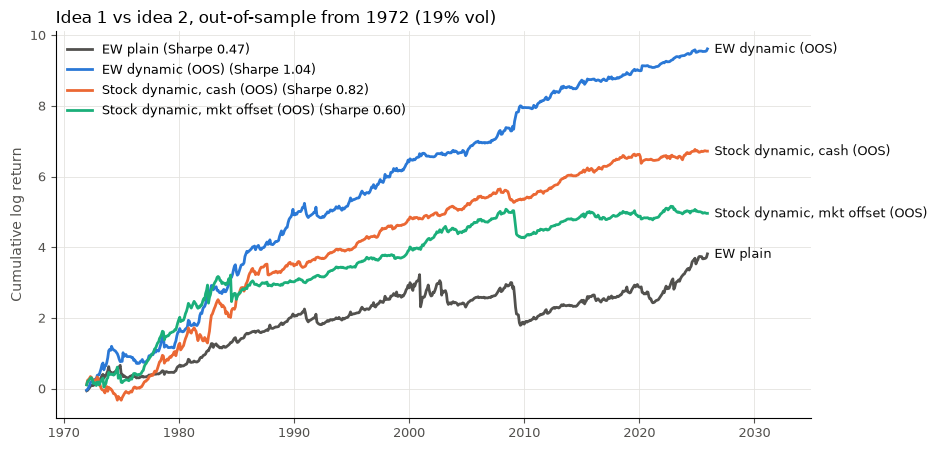

Returns in the momentum crash months (%), every strategy at 19% volatility


,VW plain,VW dynamic (OOS),EW plain,EW dynamic (OOS),"Stock dynamic, cash (OOS)","Stock dynamic, mkt offset (OOS)",Stock mix only (OOS)
month,,,,,,,
2001-01,-30.35,-7.35,-59.80,-6.49,-1.72,-4.73,-45.01
2002-11,-24.07,0.47,-29.96,3.32,1.82,-3.05,-24.58
2009-03,-27.41,0.55,-22.17,24.65,1.12,-17.48,-4.24
2009-04,-28.97,2.91,-27.72,14.21,2.34,-21.35,NaN
2020-04,-18.29,7.59,-14.53,14.85,4.11,0.69,-17.23
2020-11,-17.01,-2.69,-12.14,-2.75,0.36,-2.53,-14.71
2023-01,-22.84,1.74,-25.37,4.06,0.30,-8.23,-28.52


In [11]:
plot_cumulative(everything[["EW plain", "EW dynamic (OOS)", "Stock dynamic, cash (OOS)", "Stock dynamic, mkt offset (OOS)"]],
                [GREY, BLUE, ORANGE, AQUA], "Idea 1 vs idea 2, out-of-sample from 1972 (19% vol)", start="1972-01")

crash_months = ["2001-01", "2002-11", "2009-03", "2009-04", "2020-04", "2020-11", "2023-01"]
print("Returns in the momentum crash months (%), every strategy at 19% volatility")
display(everything.loc[crash_months, ["VW plain", "VW dynamic (OOS)", "EW plain", "EW dynamic (OOS)",
                                      "Stock dynamic, cash (OOS)", "Stock dynamic, mkt offset (OOS)", "Stock mix only (OOS)"]] * 100)

## Why idea 2 falls short

Two questions. Does the stock-level book get out of the way before a crash? And can a stock's own state tell us *which* losers will be squeezed?

Weight going into each crash month, relative to its own full-sample average


,Loser-leg stock weights,Winner-leg stock weights,Book weight w_t (idea 1)
month,,,
2001-01,0.04,0.51,0.10
2002-11,0.06,0.63,-0.90
2009-03,0.01,1.44,-2.24
2009-04,0.00,1.66,-0.75
2020-04,0.10,0.36,-1.02
2020-11,0.32,0.37,0.19
2023-01,0.15,1.17,-0.16


correlation with the book weight: {'Loser-leg stock weights': 0.4, 'Winner-leg stock weights': 0.31, 'Book weight w_t (idea 1)': 1.0}
net long share of the stock-level book (long - short) / (long + short): average 0.33, in the crash months 0.80
volatility of the cash-financed stock-level book by decade (%/yr): {1960: 26, 1970: 22, 1980: 20, 1990: 13, 2000: 13, 2010: 13, 2020: 20}


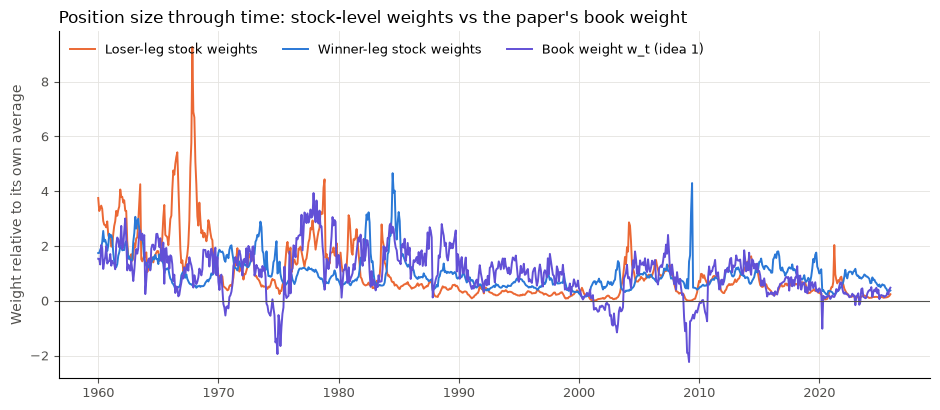

In [12]:
# Why idea 2 falls short (a): how much each approach cuts exposure going into a crash.
exposure = p.groupby(["month", "leg"]).w_is.mean().unstack()
exposure = pd.DataFrame({"Loser-leg stock weights": exposure.losers / exposure.losers.mean(),
                         "Winner-leg stock weights": exposure.winners / exposure.winners.mean(),
                         "Book weight w_t (idea 1)": w_ew["dyn (IS)"] / w_ew["dyn (IS)"].mean()})
print("Weight going into each crash month, relative to its own full-sample average")
display(exposure.loc[crash_months])
print("correlation with the book weight:", exposure.corr()["Book weight w_t (idea 1)"].round(2).to_dict())
net_long = p.groupby(["month", "leg"]).w_is.mean().unstack().pipe(lambda e: (e.winners - e.losers) / (e.winners + e.losers))
print(f"net long share of the stock-level book (long - short) / (long + short): average {net_long.mean():.2f}, "
      f"in the crash months {net_long.loc[crash_months].mean():.2f}")
print("volatility of the cash-financed stock-level book by decade (%/yr):",
      (idea2["Stock dynamic, cash (IS)"].groupby(idea2.index.year // 10 * 10).std() * np.sqrt(12) * 100).round(0).astype(int).to_dict())

fig, ax = plt.subplots(figsize=(9.5, 4.2))
for name, color in zip(exposure, [ORANGE, BLUE, VIOLET]):
    ax.plot(exposure.index.to_timestamp(), exposure[name], color=color, lw=1.4, label=name)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_title("Position size through time: stock-level weights vs the paper's book weight", loc="left", fontsize=12)
ax.set_ylabel("Weight relative to its own average", color=GREY)
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=GREY, labelsize=9)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=3)
fig.tight_layout(); plt.show()

In [13]:
# Why idea 2 falls short (b): does a stock's own state tell us which losers get squeezed?
p["var_quintile"] = p.groupby(["month", "leg"])["var"].transform(lambda v: pd.qcut(v.rank(method="first"), 5, labels=False) + 1)
print("Average position return by own-variance quintile (%/month; 1 = calmest stocks in the leg)")
display(p.groupby(["leg", "var_quintile"]).x.mean().unstack() * 100)

p["own_state"] = np.where(p.bear_var > p.groupby(["month", "leg"]).bear_var.transform("median"), "high", "low")
loser_halves = p[p.leg == "losers"].groupby(["month", "own_state"]).ret.mean().unstack()
print("Loser returns in the crash months (%), split at the median of own bear x own variance")
display((loser_halves.loc[crash_months] * 100).rename(columns={"high": "high own state", "low": "low own state"})
        .assign(market=monthly_ew.mkt.loc[crash_months] * 100))

# Table 4 of the paper for the two halves: is the bear-market up-beta (the option) larger in the high half?
m = in_sample(monthly_ew.assign(**{"low own state": loser_halves.low, "high own state": loser_halves.high}), FULL)
print("Table 4-style regression of loser portfolios on the market (market-level bear and up-market flags)")
display(tables.optionality(m, "IB", portfolios=["low own state", "high own state"])[["low own state", "high own state"]])

# Let each stock's loading on the market panic variable depend on its own state (rank within leg, -0.5 .. 0.5)
q = p.join((monthly_ew.IB * monthly_ew.var_m).rename("panic"), on="month")
q["own_rank"] = q.groupby(["month", "leg"]).bear_var.rank(pct=True) - 0.5
q["panic_x_own"] = q.panic * q.own_rank
rows = {}
for leg, df in q.groupby("leg"):
    fit = pooled(df, ["panic", "own_rank", "panic_x_own"])
    rows[leg] = {v: f"{fit.params[v] * 100:.2f} [{fit.tvalues[v]:.2f}]" for v in fit.params.index}
print("Position return on market panic (bear x market variance), own-state rank, and their interaction (%/month)")
display(pd.DataFrame(rows))

Average position return by own-variance quintile (%/month; 1 = calmest stocks in the leg)


var_quintile,1,2,3,4,5
leg,,,,,
losers,-0.05,0.29,0.49,0.46,0.73
winners,0.80,0.92,0.91,0.78,0.24


Loser returns in the crash months (%), split at the median of own bear x own variance


own_state,high own state,low own state,market
month,,,
2001-01,99.75,75.47,3.79
2002-11,48.24,45.83,6.08
2009-03,47.33,26.73,9.03
2009-04,33.23,54.32,10.18
2020-04,38.73,43.37,13.60
2020-11,39.12,39.14,12.46
2023-01,37.40,42.39,6.96


Table 4-style regression of loser portfolios on the market (market-level bear and up-market flags)


,low own state,high own state
alpha_0,-0.945 [-3.81],-1.228 [-3.30]
alpha_B,2.804 [2.30],3.395 [1.85]
beta_0,1.353 [22.62],1.425 [15.87]
beta_B,0.434 [1.86],0.550 [1.57]
beta_BU,0.110 [0.29],-0.163 [-0.29]
R2 (%),52.2,34.4
N,792,792


Position return on market panic (bear x market variance), own-state rank, and their interaction (%/month)


,losers,winners
const,0.88 [2.66],0.76 [4.03]
panic,-61.94 [-3.56],-3.26 [-0.86]
own_rank,0.11 [0.22],-0.32 [-0.69]
panic_x_own,5.39 [0.18],25.66 [2.27]


## Robustness

The conclusion does not hinge on the exact weight formula. No variant of the mix-only book gets far above the plain equal-dollar WML (0.52), so the gains in the other two columns come from changing the size of the legs, not from picking stocks.

In [14]:
# Robustness: other ways to turn the stock-level forecast into a weight (in-sample Sharpe ratios, 1960-2025).
def sharpe(r):
    r = r.loc["1960-01":].dropna()
    return r.mean() / r.std() * np.sqrt(12)


mu_rich = pd.Series(np.nan, index=p.index)
for leg, df in p.groupby("leg"):
    cols = ["bear", "var", "bear_var"]
    mu_rich[df.index] = pooled(df, cols).predict(sm.add_constant(df[cols]))

variants = {
    "mu / sigma^2 (the paper's formula, used above)": p.mu_is.clip(lower=0) / p["var"],
    "mu / sigma^2, no floor at zero": p.mu_is / p["var"],
    "mu / sigma^2, richer forecast (bear, var, bear x var)": mu_rich.clip(lower=0) / p["var"],
    "mu / sigma": p.mu_is.clip(lower=0) / np.sqrt(p["var"]),
    "mu only": p.mu_is.clip(lower=0),
    "1 / sigma (no forecast)": p.w_ivol,
}
rows = {}
for name, weight in variants.items():
    p["w_tmp"] = weight
    rows[name] = {"cash-financed": sharpe(bottom_up("w_tmp", "cash")), "market offset": sharpe(bottom_up("w_tmp", "market")),
                  "mix only": sharpe(composition_only("w_tmp")) if (weight >= 0).all() else np.nan}
p = p.drop(columns="w_tmp")
display(pd.DataFrame(rows).T)
print(f"for reference: EW plain {sharpe(idea1['EW plain']):.2f}, EW dynamic (IS) {sharpe(idea1['EW dynamic (IS)']):.2f}")

,cash-financed,market offset,mix only
"mu / sigma^2 (the paper's formula, used above)",1.10,0.75,0.50
"mu / sigma^2, no floor at zero",1.11,0.76,NaN
"mu / sigma^2, richer forecast (bear, var, bear x var)",1.14,0.81,0.59
mu / sigma,1.23,1.00,0.56
mu only,1.02,0.91,0.62
1 / sigma (no forecast),1.11,0.85,0.49


for reference: EW plain 0.52, EW dynamic (IS) 1.09


## Caveats

- **Gross returns.** No trading costs, short fees or price impact. Equal dollars in every decile-1 stock means large positions in very small, illiquid names; the January 2001 loser rebound of 88% is unlikely to be tradable at size.
- **Own variance is realized, not forecast.** A GARCH per stock is impractical for about 800 stocks a month. Own variance is clipped at the 5th and 95th percentile within each leg and month so stale-priced stocks do not get unbounded weights.
- **Scaling to 19% uses full-sample volatility**, as in the paper and the replication, including for the out-of-sample rows.
- **The cash-financed stock-level book is not market-neutral.** Read its appraisal ratio, not its Sharpe ratio.
- **No company names.** The CRSP extract has `permno` only, so individual stocks cannot be named here.